# Step 0 — can the features tell which cycle a person came from?

A diagnostic run before modelling, not a target to push down (decided 10/29). A feature that separates cycles sharply, and jumps between two adjacent cycles rather than drifting, usually means a question or its coding changed and the change was not harmonised. The depression model could learn the survey year from it instead of the person.

1. **All features:** 7-class XGBoost predicting the cycle, 5-fold stratified CV (out-of-fold). Reports accuracy vs chance, one-vs-rest AUROC per cycle and gain importance.
2. **Each feature alone:** its cycle-AUROC (macro one-vs-rest, from a small per-feature model) and its largest jump between adjacent cycles in standardised mean, against the spread of the others.

**Input:** `$NHANES_WORK/features/features_2005_2018.csv.gz`, `feature_dictionary.csv`
**Output:** `$NHANES_WORK/modeling/step0/` `cycle_check_features.csv`, `cycle_check_report.txt`

`RUN = True` recomputes (about 15 minutes on 4 threads); `RUN = False` only shows the saved results.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "nhanes" / "paths.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("run this notebook from inside the repository")
sys.path.insert(0, str(ROOT))
from nhanes.paths import RESULTS, THREADS, WORK  # noqa: E402

RUN = False  # True: recompute and overwrite $NHANES_WORK/modeling/step0
RUN = RUN or os.environ.get("NHANES_RUN") == "1"

FEAT = WORK / "features"
OUT = RESULTS / "step0"
NOT_FEATURES = ["SEQN", "cycle", "SDMVPSU", "SDMVSTRA", "WTINT2YR", "WTMEC2YR", "PHQ9", "depression"]
SEED = 42
PARAMS = dict(n_estimators=300, max_depth=4, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
              tree_method="hist", n_jobs=THREADS, random_state=SEED)

## Run

In [2]:
if RUN:
    import xgboost as xgb
    from sklearn.metrics import accuracy_score, roc_auc_score
    from sklearn.model_selection import StratifiedKFold

    def oof_proba(X, y, params):
        proba = np.zeros((len(y), y.max() + 1))
        gain = pd.Series(0.0, index=X.columns)
        for tr, te in StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, y):
            m = xgb.XGBClassifier(objective="multi:softprob", **params).fit(X.iloc[tr], y[tr])
            proba[te] = m.predict_proba(X.iloc[te])
            g = m.get_booster().get_score(importance_type="total_gain")
            gain = gain.add(pd.Series(g).reindex(X.columns).fillna(0), fill_value=0)
        return proba, gain / gain.sum()

    def adjacent_jump(x, cycle, order):
        """Largest |mean(c+1) - mean(c)| over adjacent cycles, in SD units, and where it happens."""
        sd = x.std()
        if not sd or np.isnan(sd):
            return 0.0, ""
        means = x.groupby(cycle).mean().reindex(order) / sd
        jumps = means.diff().abs()
        return float(jumps.max()), f"{order[int(jumps.values[1:].argmax())]}→{order[int(jumps.values[1:].argmax()) + 1]}"

    OUT.mkdir(parents=True, exist_ok=True)
    df = pd.read_csv(FEAT / "features_2005_2018.csv.gz")
    dic = pd.read_csv(FEAT / "feature_dictionary.csv").set_index("column")
    feats = [c for c in df.columns if c not in NOT_FEATURES]
    order = sorted(df.cycle.unique())
    y = df.cycle.map({c: i for i, c in enumerate(order)}).to_numpy()
    X = df[feats]

    proba, gain = oof_proba(X, y, PARAMS)
    acc = accuracy_score(y, proba.argmax(1))
    per_cycle = {c: roc_auc_score(y == i, proba[:, i]) for i, c in enumerate(order)}

    single = dict(n_estimators=60, max_depth=3, learning_rate=0.2, tree_method="hist", n_jobs=THREADS, random_state=SEED)
    rows = []
    for f in feats:
        p, _ = oof_proba(X[[f]], y, single)
        auc = roc_auc_score(y, p, multi_class="ovr", average="macro")
        jump, where = adjacent_jump(X[f].where(X[f] != -1), df.cycle, order)  # -1 = not applicable
        miss = X[f].isna().groupby(df.cycle).mean()
        rows.append({"feature": f, "kind": dic.kind.get(f, ""), "label": dic.rule.get(f, ""),
                     "cycle_auc": round(auc, 4), "gain_share": round(float(gain[f]), 4),
                     "max_adjacent_jump_sd": round(jump, 3), "jump_at": where,
                     "missing_spread": round(float(miss.max() - miss.min()), 4)})
    res = pd.DataFrame(rows).sort_values("cycle_auc", ascending=False)
    res.to_csv(OUT / "cycle_check_features.csv", index=False)

    flag = res[(res.cycle_auc >= 0.60) | (res.max_adjacent_jump_sd >= 0.3)]
    lines = [f"people: {len(df)}  features: {len(feats)}  cycles: {len(order)}",
             "", f"all features, 7-class XGBoost, 5-fold out-of-fold: accuracy {acc:.3f} "
             f"(chance = largest cycle share {pd.Series(y).value_counts(normalize=True).max():.3f})",
             "one-vs-rest AUROC per cycle (0.5 = cannot tell this cycle apart):",
             *[f"  {c}: {a:.3f}" for c, a in per_cycle.items()],
             "", "top 25 features by share of the model's gain:",
             res.sort_values("gain_share", ascending=False).head(25)[
                 ["feature", "kind", "gain_share", "cycle_auc", "max_adjacent_jump_sd", "jump_at"]].to_string(index=False),
             "", "single-feature cycle AUROC (macro one-vs-rest) distribution:",
             pd.cut(res.cycle_auc, [0, 0.52, 0.55, 0.6, 0.7, 1]).value_counts(sort=False).to_string(),
             "", f"flagged (single-feature cycle AUROC >= 0.60 or an adjacent-cycle jump >= 0.3 SD): {len(flag)}",
             flag[["feature", "kind", "cycle_auc", "max_adjacent_jump_sd", "jump_at", "missing_spread", "label"]]
             .to_string(index=False, max_colwidth=70)]
    (OUT / "cycle_check_report.txt").write_text("\n".join(lines) + "\n")

## Results

In [3]:
print((OUT / "cycle_check_report.txt").read_text())

people: 33498  features: 317  cycles: 7

all features, 7-class XGBoost, 5-fold out-of-fold: accuracy 0.753 (chance = largest cycle share 0.156)
one-vs-rest AUROC per cycle (0.5 = cannot tell this cycle apart):
  2005-06: 0.999
  2007-08: 0.963
  2009-10: 0.906
  2011-12: 0.901
  2013-14: 0.935
  2015-16: 0.983
  2017-18: 0.998

top 25 features by share of the model's gain:
    feature       kind  gain_share  cycle_auc  max_adjacent_jump_sd         jump_at
     LBXSCR        raw      0.1405     0.7373                 0.086 2013-14→2015-16
    LBXSKSI        raw      0.0648     0.6419                 0.399 2015-16→2017-18
     LBXRDW        raw      0.0520     0.6472                 0.485 2011-12→2013-14
     LBXSTB        raw      0.0493     0.6199                 0.287 2013-14→2015-16
   LBXSCLSI        raw      0.0441     0.5799                 0.721 2015-16→2017-18
   DR_TP225  diet_mean      0.0427     0.5869                 0.145 2007-08→2009-10
     LBXSBU        raw      0.0373  

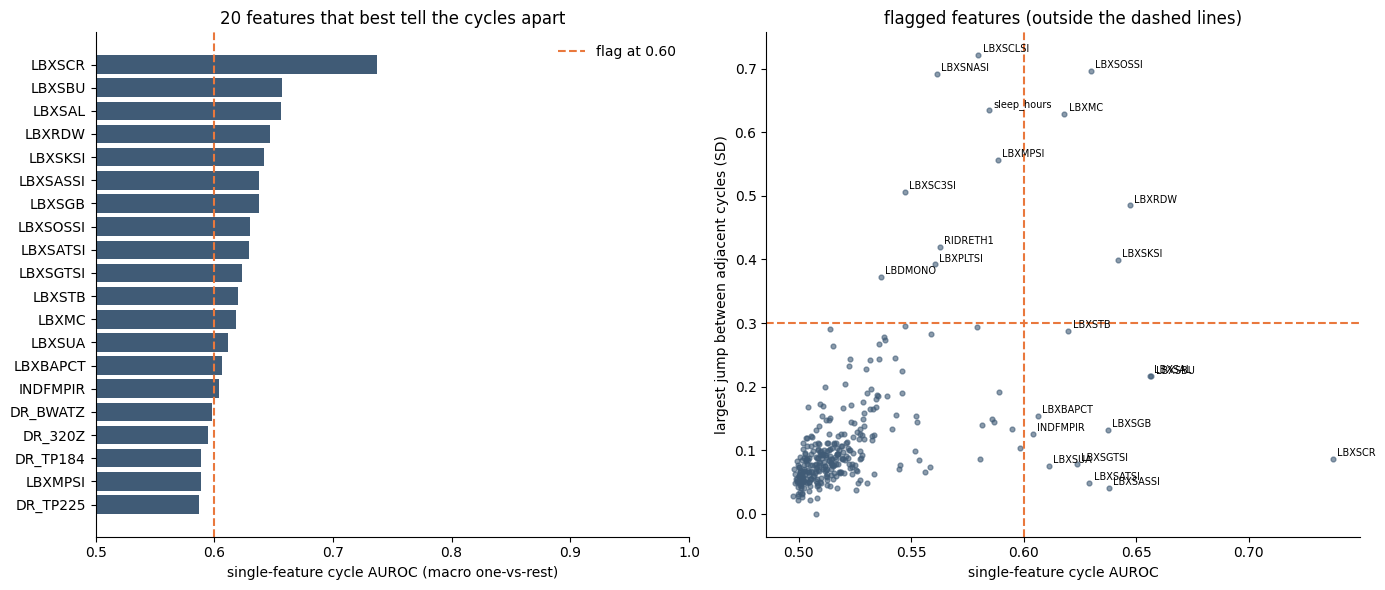

In [4]:
res = pd.read_csv(OUT / "cycle_check_features.csv")
top = res.sort_values("cycle_auc", ascending=False).head(20).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(top.feature, top.cycle_auc, color="#405B76")
axes[0].axvline(0.6, color="#E9783D", ls="--", label="flag at 0.60")
axes[0].set_xlim(0.5, max(1.0, top.cycle_auc.max()))
axes[0].set_xlabel("single-feature cycle AUROC (macro one-vs-rest)")
axes[0].set_title("20 features that best tell the cycles apart")
axes[0].legend(frameon=False)
axes[1].scatter(res.cycle_auc, res.max_adjacent_jump_sd, s=12, alpha=0.6, color="#405B76")
axes[1].axvline(0.6, color="#E9783D", ls="--")
axes[1].axhline(0.3, color="#E9783D", ls="--")
for r in res[(res.cycle_auc >= 0.6) | (res.max_adjacent_jump_sd >= 0.3)].itertuples():
    axes[1].annotate(r.feature, (r.cycle_auc, r.max_adjacent_jump_sd), fontsize=7, xytext=(3, 2), textcoords="offset points")
axes[1].set_xlabel("single-feature cycle AUROC")
axes[1].set_ylabel("largest jump between adjacent cycles (SD)")
axes[1].set_title("flagged features (outside the dashed lines)")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()